# Method 3 · U-Net + ConvLSTM + SFLA

Binary tumour segmentation with a 2D U-Net, mask-driven ROI extraction, then four-class typing with a ConvLSTM classifier whose hyper-parameters are chosen by a Shuffled Frog Leaping Algorithm search. A second SFLA search selects which of the ConvLSTM's features an SVM classifies; the head that scores higher on validation is the one served.

**Modality:** MRI
**Classifier:** ConvLSTM (Conv+BN feature stack → ConvLSTM cell → dense → softmax), or an SVM on SFLA-selected ConvLSTM features — whichever wins on validation macro-F1
**Segmentation:** U-Net (encoder/decoder, skip connections, BatchNorm, dropout). Implemented in 2D on slices; a volumetric 3D U-Net needs BraTS volumes and is not trained.
**Optimisation:** SFLA (Shuffled Frog Leaping Algorithm), twice: over the classifier's hyper-parameters, and over the feature subset plus SVM hyper-parameters

Nothing here trains anything. Every number is read from a recorded evaluation,
every image is produced by the checkpoint on disk, and the training commands are
printed rather than run.

## 1 · Setup

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "backend").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np

from backend import config
from backend.methods.registry import get_method, load_engine, runtime_status
from backend.methods.common.metrics_store import read_metrics, metrics_for

plt.rcParams["figure.dpi"] = 110
print("project root :", ROOT)
print("device       :", config.DEVICE)
print("dataset      :", config.BRI_DATASET_PATH)

project root : /Users/syedasif/tumb
device       : mps
dataset      : /Users/syedasif/tumb/data/bri/archive


In [2]:
import json

def show(images, titles, width=4.2):
    """Draw images side by side with their titles."""
    images = [i for i in images if i is not None]
    fig, axes = plt.subplots(1, len(images), figsize=(width * len(images), width))
    for ax, image, title in zip(np.atleast_1d(axes), images, titles):
        ax.imshow(image if image.ndim == 2 else image[..., ::-1], cmap="gray" if image.ndim == 2 else None)
        ax.set_title(title, fontsize=10)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


def read(path):
    import cv2
    return None if path is None else cv2.imread(str(path), cv2.IMREAD_UNCHANGED)


def table(rows, headers):
    """A plain-text table, so the notebook reads the same with or without pandas."""
    widths = [max(len(str(r[i])) for r in [headers, *rows]) for i in range(len(headers))]
    line = "  ".join(h.ljust(w) for h, w in zip(headers, widths))
    print(line)
    print("  ".join("-" * w for w in widths))
    for row in rows:
        print("  ".join(str(c).ljust(w) for c, w in zip(row, widths)))

In [3]:
METHOD = "method1"
spec = get_method(METHOD)
status = runtime_status(spec)

print(f"Method {spec.display_number} — {spec.display_name}\n")
for stage in spec.pipeline:
    print(f"  {stage.id:<16}{stage.label:<28}{stage.description}")
print()
table([[role, w["architecture"], "yes" if w["present"] else "NO", w["model_version"] or "—"]
       for role, w in status["weights"].items()],
      ["role", "architecture", "checkpoint", "version"])

Method 3 — 3D U-Net–ConvLSTM–SFLA-Based Anomaly Segmentation & Classification

  input           Input MRI                   Single MRI slice (PNG/JPG/TIFF).
  collect         Data collection             BraTS 2020/2023 volumes and the Kaggle 4-class MRI set.
  preprocess      Preprocessing               Grayscale, denoise, CLAHE, resize, min-max normalise.
  segment         U-Net segmentation          2D U-Net encoder/decoder with skip connections; binary whole-tumour mask.
  roi             ROI crop                    Bounding box of the mask, padded, resampled to the model input size.
  classify        ConvLSTM classification     Conv feature stack + ConvLSTM cell + dense head.
  sfla            SFLA optimization           Shuffled Frog Leaping search over classifier hyper-parameters (train/val only).
  features        Feature extraction          The ConvLSTM's penultimate dense layer becomes a fixed feature vector per image.
  sfla_features   SFLA feature selection      A second SF

## 2 · The data

The images below come from the dataset's own **Testing** folder — the held-out
split the metrics further down were measured on. They are examples, not
predictions.

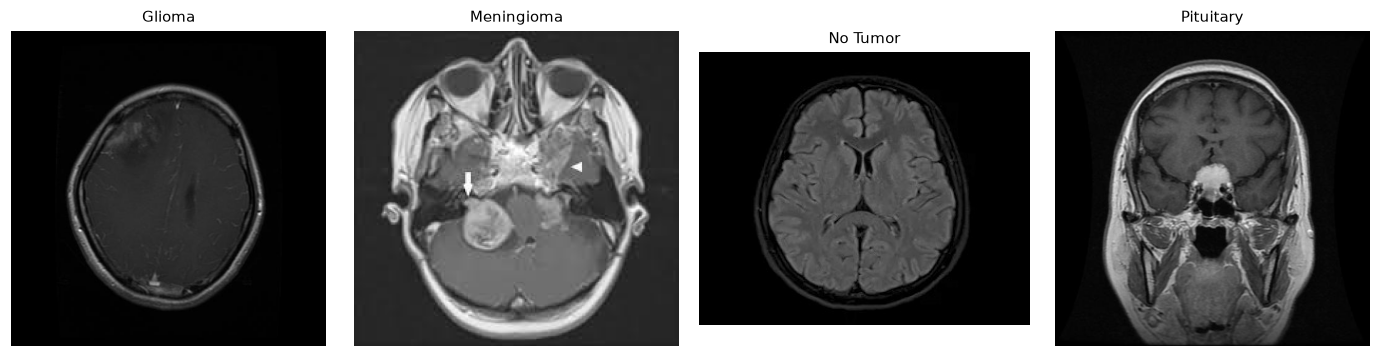

class       example file    
----------  ----------------
Glioma      Te-glTr_0002.jpg
Meningioma  Te-meTr_0002.jpg
No Tumor    Te-noTr_0002.jpg
Pituitary   Te-piTr_0002.jpg


In [4]:
# Each method's notebook looks at *different* images, so four notebooks open
# side by side show four sets of scans rather than the same one four times.
# OFFSET is this method's display number; it only shifts which examples are
# shown, never which images anything was trained or measured on.
OFFSET = 2
FOCUS = "notumor"

root = config.BRI_DATASET_PATH / "Testing"
samples = {}
for class_key in spec.class_names:
    folder = root / ({"normal": "notumor"}.get(class_key, class_key))
    files = sorted(folder.glob("*.jpg")) if folder.is_dir() else []
    if files:
        # A clone ships one or two images per class; a full dataset has hundreds.
        samples[spec.class_labels[class_key]] = files[min(OFFSET, len(files) - 1)]

show([read(p) for p in samples.values()], list(samples), width=3.2)
table([[label, path.name] for label, path in samples.items()], ["class", "example file"])

## 3 · Preprocessing

The geometry is read from the checkpoint, not chosen here: a model is served the
same transform it was trained with.

In [5]:
engine = load_engine(METHOD)
engine.load()
transform = status["weights"].get("classification", {}).get("transform_id")
print("transform recorded in the checkpoint:", transform or "—")

import importlib
transforms = importlib.import_module(spec.transforms_module)
spec_obj = transforms.get_spec(transform) if hasattr(transforms, "get_spec") else transforms.DEFAULT_SPEC
for k, v in spec_obj.to_dict().items():
    print(f"  {k:<16}{v}")

transform recorded in the checkpoint: m1-v1-legacy
  id              m1-v1-legacy
  image_size      128
  order           denoise_then_resize
  denoise         True
  clahe           True
  roi_crop        False
  roi_pad         8
  roi_min_pixels  20
  description     Original geometry: full-resolution non-local-means denoise, CLAHE, then resize; classifier sees the whole slice, never an ROI crop. Used for the untagged classifier checkpoint shipped with the repository.


## 4 · The model as loaded

Built from the checkpoint's own record of its hyper-parameters, then the stored
weights are loaded into it. A checkpoint that belonged to another method, or to
other classes, is refused rather than coerced.

In [6]:
model = getattr(engine, "model", None) or getattr(engine, "cls_model", None)
print(type(model).__name__)
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")
print()
for key, value in (engine.meta if hasattr(engine, "meta") else engine.cls_meta).items():
    if key != "extra":
        print(f"  {key:<18}{value}")

ConvLSTMClassifier
589,684 parameters

  format            2
  method_id         method1
  architecture      ConvLSTMClassifier
  role              classification
  class_names       ['glioma', 'meningioma', 'notumor', 'pituitary']
  image_size        128
  transform_id      m1-v1-legacy
  model_version     20260916-221953
  created_at        2026-09-16T22:19:53+00:00


## 5 · One prediction, with everything it produced

The class, the probabilities, and every image this method writes: the
preprocessed input it actually read, the segmentation mask, the Grad-CAM
heatmap, and — for the fusion method — the fused image.

In [7]:
# FOCUS differs per method, so each notebook demonstrates a different class.
image_path = samples.get(spec.class_labels[FOCUS], list(samples.values())[0])
result = engine.predict(image_path.read_bytes())

print(f"input      : {image_path}")
print(f"prediction : {result.prediction}   {result.confidence}%")
print(f"model      : {result.model_version}   ({result.inference_time_s}s)\n")
for name, value in sorted(result.probabilities.items(), key=lambda kv: -kv[1]):
    print(f"  {name:<14}{'█' * int(value / 4):<25}{value:6.2f}%")

input      : /Users/syedasif/tumb/data/bri/archive/Testing/notumor/Te-noTr_0002.jpg
prediction : No Tumor   96.25%
model      : 20261017-145311   (0.2154s)

  No Tumor      ████████████████████████  96.25%
  Meningioma                               3.75%
  Glioma                                   0.00%
  Pituitary                                0.00%


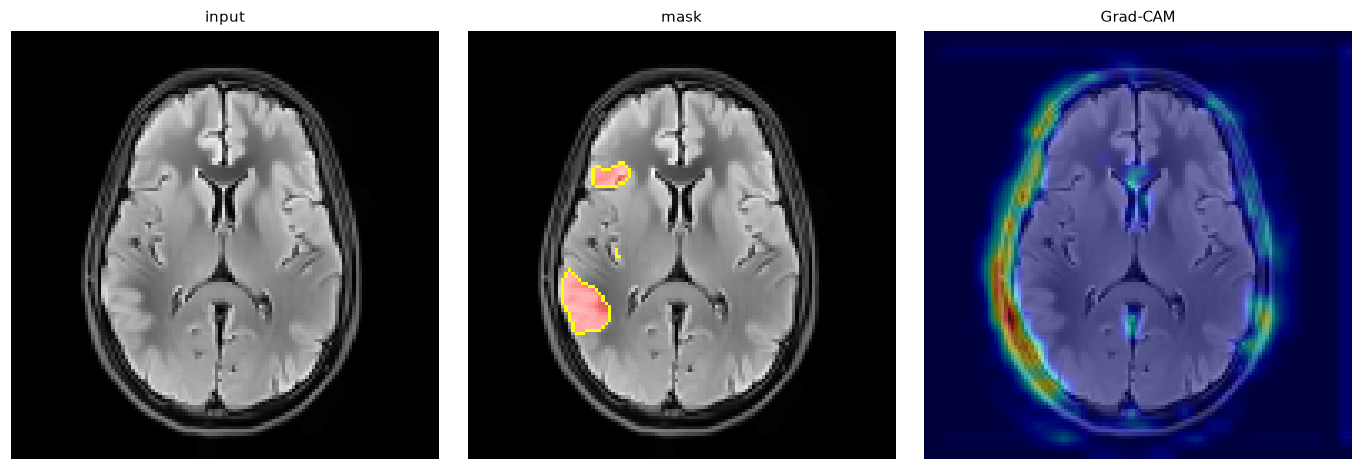

Grad-CAM: The heatmap explains the ConvLSTM that produced the features, not the SVM's decision boundary.


In [8]:
panels = [("input", result.original_path), ("mask", result.mask_path),
          ("Grad-CAM", result.overlay_path), ("fused", getattr(result, "fused_path", None))]
panels = [(label, path) for label, path in panels if path]
show([read(p) for _, p in panels], [label for label, _ in panels])

note = result.details.get("segmentation_note")
if note:
    print("mask:", note)
if result.details.get("gradcam_note"):
    print("Grad-CAM:", result.details["gradcam_note"])

## 6 · The recorded held-out evaluation

These numbers are not computed here. They were measured once, by the training
run, on the test split — and are read back from the metrics file so this
notebook cannot quietly disagree with the API.

In [9]:
metrics = metrics_for(METHOD)
table([[k, f"{metrics[k]:.4f}" if metrics[k] is not None else "—"]
       for k in ("accuracy", "precision", "recall", "specificity", "f1", "auc", "dice", "iou")],
      ["metric", "held-out test"])
print()
print(metrics["split"])

metric       held-out test
-----------  -------------
accuracy     0.9695       
precision    0.9688       
recall       0.9707       
specificity  0.9899       
f1           0.9697       
auc          0.9944       
dice         0.6558       
iou          0.5696       

dataset Training/Testing split; validation carved from Training only; image-level split; no patient identifiers, patient-grouped held-out test


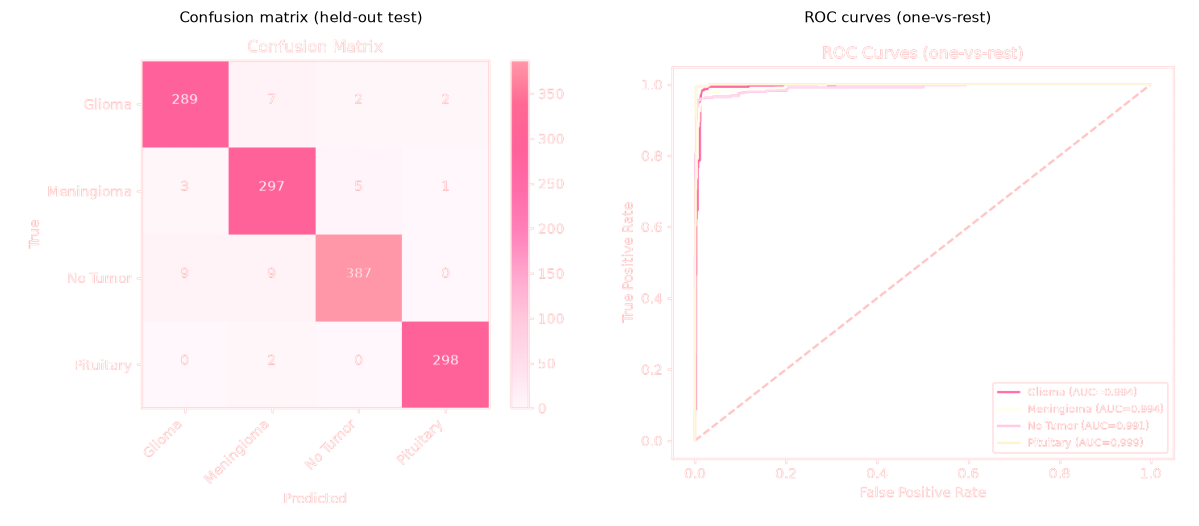

In [10]:
show([read(config.LOGS_DIR / "method1_cls_confusion_matrix.png"),
      read(config.LOGS_DIR / "method1_cls_roc.png")],
     ["Confusion matrix (held-out test)", "ROC curves (one-vs-rest)"], width=5.5)

## 7 · SFLA feature selection, and the geometry that lost

Two searches, both scored on validation only. The first chose the ConvLSTM's
hyper-parameters; the second chose which of its 128 features an SVM should
classify. Separately, the ROI-cropped geometry the architecture diagram shows
was trained to convergence and **lost** to whole slices on validation, so whole
slices are what the served checkpoint uses.

In [11]:
search = json.loads((config.LOGS_DIR / "method1/sfla_feature_selection.json").read_text())
print(f"kept        : {search['features_selected']} of {search['features_available_to_search']} features")
print(f"SVM         : {search['svm']}")
print(f"evaluations : {search['evaluations']} in {search['duration_s']:.0f}s")
print(f"served head : {search['served_head']}")
print()
table([[k, f"{v['f1']:.4f}"] for k, v in search["validation"].items()], ["head", "validation F1"])
table([[k, f"{v['accuracy']:.4f}", f"{v['f1']:.4f}"] for k, v in search["test"].items()],
      ["head", "TEST accuracy", "TEST macro F1"])

kept        : 36 of 98 features
SVM         : {'C': 8.53622763207344, 'gamma': 0.020417821288915457, 'kernel': 'linear', 'class_weight': 'balanced', 'probability': 'Platt scaling'}
evaluations : 1850 in 33s
served head : sfla_svm

head              validation F1
----------------  -------------
sfla_svm          0.9893       
convlstm_softmax  0.9775       
head              TEST accuracy  TEST macro F1
----------------  -------------  -------------
sfla_svm          0.9695         0.9697       
convlstm_softmax  0.9641         0.9643       


In [12]:
geometry = json.loads((config.LOGS_DIR / "method1/roi_geometry_comparison.json").read_text())
print(geometry["question"])
print(f"decided on  : {geometry['decided_on']}\n")
table([[name, c["transform_id"], f"{c['validation']['f1']:.4f}", c["best_epoch"]]
       for name, c in geometry["candidates"].items()],
      ["candidate", "transform", "validation F1", "best epoch"])
print(f"\nchosen: {geometry['decision']}")
for note in geometry["notes"]:
    print(" •", note)

Should the ConvLSTM classify the U-Net's ROI crop (the geometry the architecture diagram shows) or the whole slice?
decided on  : validation macro-F1 only; neither run loaded the test split

candidate      transform     validation F1  best epoch
-------------  ------------  -------------  ----------
whole_slice    m1-v1-legacy  0.9775         46        
unet_roi_crop  m1-v2-roi     0.9595         88        

chosen: whole_slice
 • Both runs used the same split, the same seed and the same default hyper-parameters; they differ only in the input geometry.
 • The ROI run was given 120 epochs with patience 15 and early-stopped at 103, so it was trained to convergence rather than cut off by the epoch cap. An earlier 40-epoch run reached 0.9439 and was still improving, which is why it was repeated.
 • Why the crop loses: the segmentation it depends on scores Dice 0.656, so a crop often cuts into or misses the lesion, and the context outside the box — which the whole-slice model can still use 

### The volumetric model

A 3D U-Net was trained on 484 Decathlon (BraTS) volumes, split by patient. It is
**not** what segments an upload — an upload is one slice and a 3D model needs the
slices around it — so its Dice is reported on its own.

In [13]:
volumetric = read_metrics("method1").get("segmentation_3d") or {}
if volumetric:
    table([[volumetric["architecture"], volumetric["dice"], volumetric["decision_threshold"],
            volumetric["volumes"], volumetric["predicted_to_true_volume_ratio"]]],
          ["model", "TEST Dice", "threshold", "volumes", "predicted/true volume"])
    print("\nthreshold chosen on validation:")
    for row in json.loads((config.LOGS_DIR / "method1/segmentation3d_metrics.json").read_text())["validation_threshold_sweep"]:
        print(f"   {row['threshold']:.2f} -> Dice {row['dice']:.4f}  (volume ratio {row['predicted_to_true_volume_ratio']})")
else:
    print("No volumetric model trained on this machine.")

model   TEST Dice  threshold  volumes  predicted/true volume
------  ---------  ---------  -------  ---------------------
UNet3D  0.5091     0.8        72       1.211                

threshold chosen on validation:
   0.50 -> Dice 0.4548  (volume ratio 2.456)
   0.60 -> Dice 0.4854  (volume ratio 2.004)
   0.70 -> Dice 0.5087  (volume ratio 1.6)
   0.80 -> Dice 0.5178  (volume ratio 1.187)
   0.90 -> Dice 0.4788  (volume ratio 0.681)
   0.95 -> Dice 0.3807  (volume ratio 0.401)


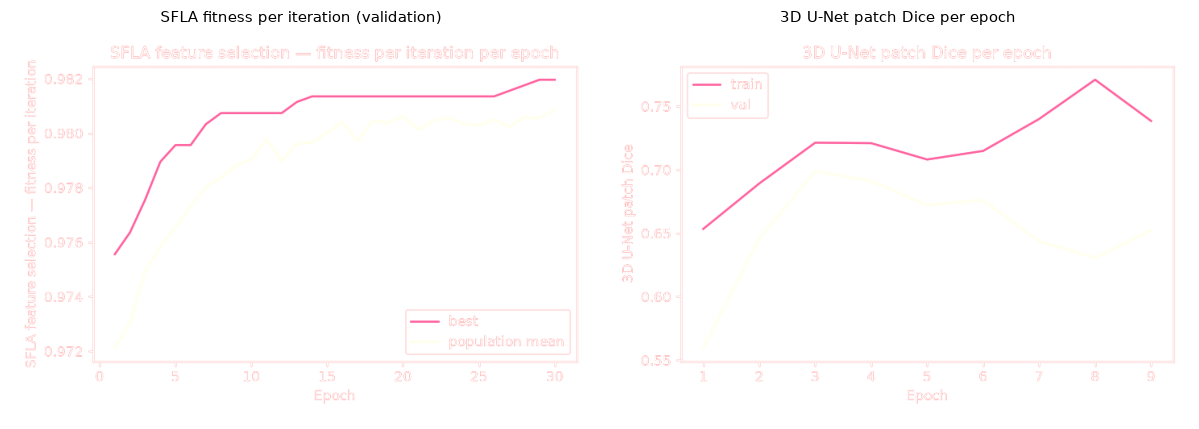

In [14]:
show([read(config.LOGS_DIR / "method1/sfla_feature_selection.png"),
      read(config.LOGS_DIR / "method1/seg3d_dice.png")],
     ["SFLA fitness per iteration (validation)", "3D U-Net patch Dice per epoch"], width=5.5)

## 8 · Caveats

Every warning the method records travels with its numbers. They are part of the
result, not a footnote to it.

In [15]:
seen = set()
for section, values in read_metrics(METHOD).items():
    if not isinstance(values, dict):
        continue
    for warning in values.get("warnings", []) or []:
        if warning not in seen:
            seen.add(warning)
            print(f"[{section}] {warning}\n")

[classification] The Kaggle brain-MRI classification dataset carries no patient identifiers, so samples can only be grouped by image identity (training groups byte-identical copies together). Scores from this dataset may still be optimistic if the same patient appears under unrelated filenames.

[classification] Using the dataset's own Training/Testing split. It is an IMAGE-level split: this dataset ships no patient identifiers, so slices from one patient may appear on both sides and the test score can be optimistic.

[classification] Dropped 134 Training images that are byte-identical to a Testing image, so the test score is not inflated by memorised copies. The Testing set itself was not modified.

[classification] Two classifier heads exist for this method: the ConvLSTM's softmax layer and an SVM on SFLA-selected ConvLSTM features. The sfla_svm head is served; the choice was made on validation macro-F1 (0.9893 SVM vs 0.9775 softmax) before the test set was opened.

[classification] 

## 9 · Reproducing this

```bash
python -m backend.methods.method1.training.train_segmentation
python -m backend.methods.method1.training.train_segmentation_3d
python -m backend.methods.method1.training.train_classifier
python -m backend.methods.method1.optimization.run_sfla
python -m backend.methods.method1.training.train_feature_svm
```

Or run every method on one image from a terminal:

```bash
python -m backend.cli.run_methods data/bri/archive/Testing/glioma/Te-gl_0012.jpg
```